In [ ]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import dataframe_image as dfi
import time 

: 

In [2]:
answers = pd.read_csv("wordle_answers.csv", names=["Word"])
guesses = pd.read_csv("wordle_guesses.csv", names=["Word"])
crossTable = pd.read_csv("Outputs/AllEvaluations.csv", index_col=0)

In [8]:
#Create Graphs of the Distribution of a Specified Space in Answers
space = 1

titleDict = {1:"1st", 2:"2nd", 3:"3rd", 4:"4th", 5:"5th"}
data["index"] = data["Word"].apply(lambda x: x[space-1])
letters = data["index"].value_counts().sort_index().reset_index()

plt.bar(letters["level_0"], letters["index"])
plt.title("Count per Letter for " + titleDict[space] + " Letter of Wordle Answers")
plt.ylabel("Count")
plt.show()

NameError: name 'data' is not defined

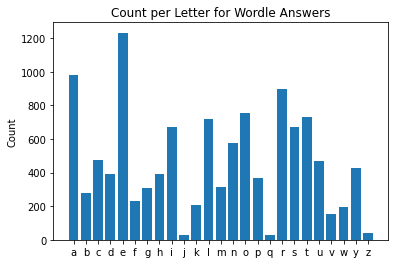

In [ ]:
#Create Graphs of the Distribution of the Total Count of Each Letter in Answers

table = pd.DataFrame({"1st":data["Word"].apply(lambda x: x[0]).value_counts()})
for indy in range(1,5):
    table = table.join(pd.DataFrame({titleDict[indy+1]:(data["Word"].apply(lambda x: x[indy]).value_counts())}))
total = table.fillna(0).sum(axis=1).sort_index().reset_index()

plt.bar(total["index"], total[0])
plt.title("Count per Letter for Wordle Answers")
plt.ylabel("Count")
plt.show()

In [ ]:
#Create Table of the Counts of each Letter in Each Space
#Replace NA with 0s should fix some problems

titleDict = {1:"1st", 2:"2nd", 3:"3rd", 4:"4th", 5:"5th"}
table = pd.DataFrame({"1st":data["Word"].apply(lambda x: x[0]).value_counts()})
for indy in range(1,5):
    table = table.join(pd.DataFrame({titleDict[indy+1]:(data["Word"].apply(lambda x: x[indy]).value_counts())}))
table["Total"] = table.sum(axis=1)
table = table.fillna(0).convert_dtypes("int64")
dfi.export(table.sort_index().style.background_gradient(axis=0), "Outputs/EachSpacesLetterCounts.png")

[0620/225500.350321:INFO:headless_shell.cc(660)] Written to file /var/folders/4f/kyq7qtn95xn102x873x29jsm0000gn/T/tmph4ut7wt2/temp.png.


## Information Theory Section

In [12]:
    # Evaluate Guessed Word
    ## Taken for Wordle Program with output changed to only display colors
    ### For Example [1,0,1,1,2] means yellow, grey, yellow, yellow, green
    def evaluateGuess(guessed, answer):
        score = [[letter, 0] for letter in guessed]
        for index in range(len(guessed)): # Green Letters
            if guessed[index] == answer[index]:
                score[index][1] = 2
                answer = answer[0:index] + "_" + answer[index+1:5]
                guessed = guessed[0:index] + "_" + guessed[index+1:5]
        for index in range(len(guessed)): # Yellow Letters
                if guessed[index] != "_" and guessed[index] in answer:
                    score[index][1] = max(1, score[index][1])
                    answer = answer.replace(score[index][0], "_", 1)
                    guessed = guessed.replace(score[index][0], "_", 1)
        for index in range(len(guessed)): # Grey Letters
            if guessed[index] != "_":
                score[index][1] = max(0, score[index][1])
        return "".join([str(letter[1]) for letter in score])

evaluateGuess("maare", "aware")

'01222'

In [ ]:
# Information Theory : Entropy Calculation
## Calculating only the entropy of the first guess
# Took 14mins 49s in Total
allWords = guesses.copy()
output = [0 for i in range(len(allWords["Word"]))]
for index, word in enumerate(allWords["Word"]):
    answersCopy = answers.copy()
    answersCopy[word] = answersCopy.apply(lambda x: evaluateGuess(word, x["Word"]), axis=1) 
    outcomeCounts = answersCopy.groupby(word).count()
    probs = outcomeCounts["Word"].values / outcomeCounts["Word"].values.sum()
    entropy = -1 * (probs * np.log2(probs)).sum()
    output[index] = [word, entropy]

result = pd.DataFrame(output, columns=["Guess", "Entropy"])
result.to_csv("Outputs/EntropyCalculations.csv", index=False)
result

In [10]:
crossTable.stack().groupby(level=0).value_counts(normalize=True).unstack().apply(lambda x : -1 * (x * np.log2(x)).sum().sum(), axis=1).sort_values(ascending=False)

soare    5.885960
roate    5.882779
raise    5.877910
raile    5.865710
reast    5.865457
           ...   
yukky    2.205266
xylyl    2.192001
immix    2.052600
jujus    2.038309
qajaq    1.891836
Length: 12972, dtype: float64

## Creating a Bot for normal mode

In [4]:
# To help the bots speed create a table of all evalutions
# Guesses x Answers 

def evaluateAllAnswers(guess, answers):
    return [evaluateGuess(guess, answer) for answer in answers["Word"]]

cols = answers["Word"]
pd.concat([pd.DataFrame([evaluateAllAnswers(word, answers)], columns=cols, index=[word]) for word in guesses["Word"]]).to_csv("Outputs/AllEvaluations.csv")

NameError: name 'evaluateGuess' is not defined

In [11]:
crossTable

,Entropy
Guess,
aback,3.499665
abase,4.573750
abate,4.617764
abbey,3.925441
abbot,3.976548
...,...
zuzim,2.709230
zygal,3.746094
zygon,3.499647


In [5]:
def subsetAnswers(guess, evaluation, possibleAnswers):
    row = possibleAnswers.loc[guess]
    return row[row == evaluation].index

#crossTable[subsetAnswers("aahed", 10000, crossTable[["junta", "tangy", "aunty"]])]

In [8]:
# Bot that returns guesses, outcomes and number of turns
# Parameters: the answer, list of guesses, ability to toggle printed output
# Returns: print guesses and evalutaions, returns number of guesses

# Hard coding the starting word because it is the same using these calculations and saves time

def wordleBot(answer, possibleAnswers, output = True, start = 'soare'):
    attempt = 1
    solved = False
    best = start
    if start == "answer":
        solved = True
    if output:
        print("{0} : {1} | {2}".format(attempt, start, possibleAnswers[answer][start]))
    while not solved:
        attempt += 1
        possibleAnswers = possibleAnswers[subsetAnswers(best, possibleAnswers[answer][best], possibleAnswers=possibleAnswers)]
        if len(possibleAnswers.columns) == 1:
            solved = True
            best = possibleAnswers.columns[0]
        else: 
            best = possibleAnswers.stack().groupby(level=0).value_counts(normalize=True).unstack(
                ).apply(lambda x : -1.1 * (x * np.log2(x)).sum() if x.name in possibleAnswers.columns else -1 * (x * np.log2(x)).sum(), axis=1 # Condition is to favor answers over guesses in case of same information
                ).sort_values(ascending=False).head(1).index[0]
        if output:
            print("{0} : {1} | {2}".format(attempt, best, possibleAnswers[answer][best]))
        if best == answer or attempt > 6:
            solved = True
    return attempt
        

wordleBot("hunky", crossTable, start="soare") 

1 : soare | 0
2 : lunch | 2201
3 : hunky | 22222


3

In [11]:
# Testing the wordleBot on all possible answers

failed = []
histogram = {i:0 for i in range(1,7)}
try:
    for index, word in enumerate(answers["Word"]):
        num = wordleBot(word, crossTable, False, "raise")
        if num > 6:
            failed.append(word)
        histogram[min(num, 6)] += 1
except:
    print(word)


print(histogram)
total = 0
for key in histogram.keys():
    total += key * histogram[key]
print(total / 2315)

{1: 0, 2: 82, 3: 1100, 4: 1054, 5: 77, 6: 2}
3.4889848812095035


Soare
Mean : 3.4907127429805613
Hist : {1: 0, 2: 70, 3: 1128, 4: 1030, 5: 85, 6: 2}

Roate
Mean : 3.485961123110151
Hist : {1: 0, 2: 83, 3: 1081, 4: 1094, 5: 57, 6: 0}

Raise
Mean : 3.4889848812095035
Hist : {1: 0, 2: 82, 3: 1100, 4: 1054, 5: 77, 6: 2}